In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Path to dataset files: /kaggle/input/hotel-booking-demand


In [2]:
import os

In [3]:
os.listdir(path)

['hotel_bookings.csv']

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [5]:
df = pd.read_csv(path + "/hotel_bookings.csv")

In [6]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
df.shape

(119390, 32)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [9]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


# Data Cleaning

In [10]:
df.isnull().sum().sort_values(ascending=False)

,0
company,112593
agent,16340
country,488
children,4
arrival_date_month,0
arrival_date_week_number,0
hotel,0
is_canceled,0
stays_in_weekend_nights,0
arrival_date_day_of_month,0


In [11]:
df.duplicated().sum()

np.int64(31994)

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df.reset_index(drop=True,inplace=True)

In [14]:
pd.crosstab(df['reservation_status'], df['is_canceled'])

is_canceled,0,1
reservation_status,,
Canceled,0,23011
Check-Out,63371,0
No-Show,0,1014


In [15]:
df.drop(['reservation_status','reservation_status_date','assigned_room_type'],axis=1,inplace=True)

In [16]:
df['is_canceled'].value_counts(normalize=True)

,proportion
is_canceled,
0,0.725102
1,0.274898


In [17]:
df['has_company'] = df['company'].notna().astype(int)
df['has_agent'] = df['agent'].notna().astype(int)

In [18]:
df.drop(['company','agent'],axis=1,inplace=True)

In [19]:
df['meal'].value_counts()

,count
meal,
BB,67978
SC,9481
HB,9085
Undefined,492
FB,360


In [20]:
df['meal'] = df['meal'].replace('Undefined','SC')

In [21]:
no_guests = (df['adults'] + df['children'].fillna(0) + df['babies']) == 0
print("no guests:", no_guests.sum())
print("negative adr:", (df['adr'] < 0).sum())
print("adr >= 5000:", (df['adr'] >= 5000).sum())

no guests: 166
negative adr: 1
adr >= 5000: 1


In [22]:
df = df[~no_guests & (df['adr'] >= 0) & (df['adr'] < 5000)]
df.reset_index(drop=True,inplace=True)
df.shape

(87228, 29)

In [23]:
months = {'January':1,'February':2,'March':3,'April':4,'May':5,'June':6,
          'July':7,'August':8,'September':9,'October':10,'November':11,'December':12}
df['arrival_month'] = df['arrival_date_month'].map(months)

In [24]:
df.drop(['arrival_date_month','arrival_date_year','arrival_date_week_number','arrival_date_day_of_month'],axis=1,inplace=True)

In [25]:
df.isnull().sum().sort_values(ascending=False)

,0
country,447
children,4
is_canceled,0
hotel,0
lead_time,0
stays_in_weekend_nights,0
adults,0
stays_in_week_nights,0
babies,0
meal,0


In [26]:
X = df.drop('is_canceled',axis = 1)
y = df['is_canceled']

In [27]:
from sklearn.model_selection import train_test_split

In [28]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,shuffle=True,random_state=42,stratify=y)

In [29]:
X_train.reset_index(drop=True,inplace=True)
X_test.reset_index(drop=True,inplace=True)

y_train.reset_index(drop=True,inplace=True)
y_test.reset_index(drop=True,inplace=True)

In [30]:
X_train.isnull().sum().sort_values(ascending=False).head()

,0
country,365
children,3
hotel,0
lead_time,0
stays_in_weekend_nights,0


In [31]:
from sklearn.impute import SimpleImputer

<Axes: ylabel='Frequency'>

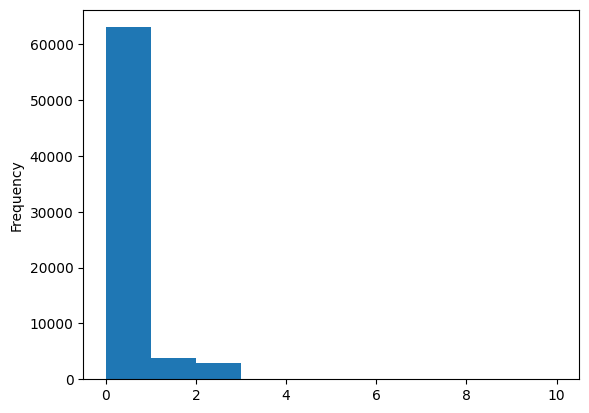

In [32]:
X_train['children'].plot(kind='hist')

In [33]:
X_train['children'].skew()

np.float64(3.461760276279195)

In [34]:
median = ['children']
mod = ['country']

In [35]:
impute_median = SimpleImputer(strategy='median')
for col in median:
    X_train[col] = impute_median.fit_transform(X_train[[col]])
    X_test[col] = impute_median.transform(X_test[[col]])

In [36]:
impute_mod = SimpleImputer(strategy='most_frequent')
for col in mod:
    X_train[[col]] = impute_mod.fit_transform(X_train[[col]])
    X_test[[col]] = impute_mod.transform(X_test[[col]])

In [37]:
X_train.isnull().sum().sum()

np.int64(0)

In [38]:
X_test.isnull().sum().sum()

np.int64(0)

In [39]:
X_train.duplicated().sum()

np.int64(1293)

In [40]:
X_test.duplicated().sum()

np.int64(82)

# Data Visualization (EDA)

| **اسم العمود** | **الوصف (المعنى)** |
| --- | --- |
| **hotel** | نوع الفندق (City Hotel أو Resort Hotel). |
| **is_canceled** | الهدف من التحليل: هل الحجز اتلغى؟ (1 = نعم، 0 = لا). |
| **lead_time** | عدد الأيام بين تاريخ الحجز وتاريخ الوصول. |
| **arrival_month** | شهر الوصول (1 إلى 12). |
| **stays_in_weekend_nights** | عدد ليالي الإقامة في عطلة نهاية الأسبوع. |
| **stays_in_week_nights** | عدد ليالي الإقامة في أيام الأسبوع. |
| **adults / children / babies** | عدد البالغين والأطفال والرضع. |
| **meal** | نوع الوجبات المحجوزة (BB, HB, FB, SC). |
| **country** | بلد العميل. |
| **market_segment** | شريحة السوق التي جاء منها الحجز. |
| **distribution_channel** | قناة توزيع الحجز. |
| **is_repeated_guest** | هل العميل زائر متكرر؟ (1 = نعم). |
| **previous_cancellations** | عدد الحجوزات السابقة اللي العميل لغاها. |
| **previous_bookings_not_canceled** | عدد الحجوزات السابقة اللي العميل ما لغاهاش. |
| **reserved_room_type** | نوع الغرفة المحجوزة. |
| **booking_changes** | عدد التعديلات على الحجز. |
| **deposit_type** | نوع الوديعة (No Deposit, Non Refund, Refundable). |
| **days_in_waiting_list** | عدد الأيام اللي الحجز قضاها في قائمة الانتظار. |
| **customer_type** | نوع العميل (Transient, Contract, Group, Transient-Party). |
| **adr** | متوسط سعر الليلة. |
| **required_car_parking_spaces** | عدد أماكن ركن العربيات المطلوبة. |
| **total_of_special_requests** | عدد الطلبات الخاصة. |
| **has_company / has_agent** | هل الحجز عن طريق شركة أو وكيل؟ (1 = نعم). |

In [41]:
df_train = pd.concat([X_train,y_train],axis=1)

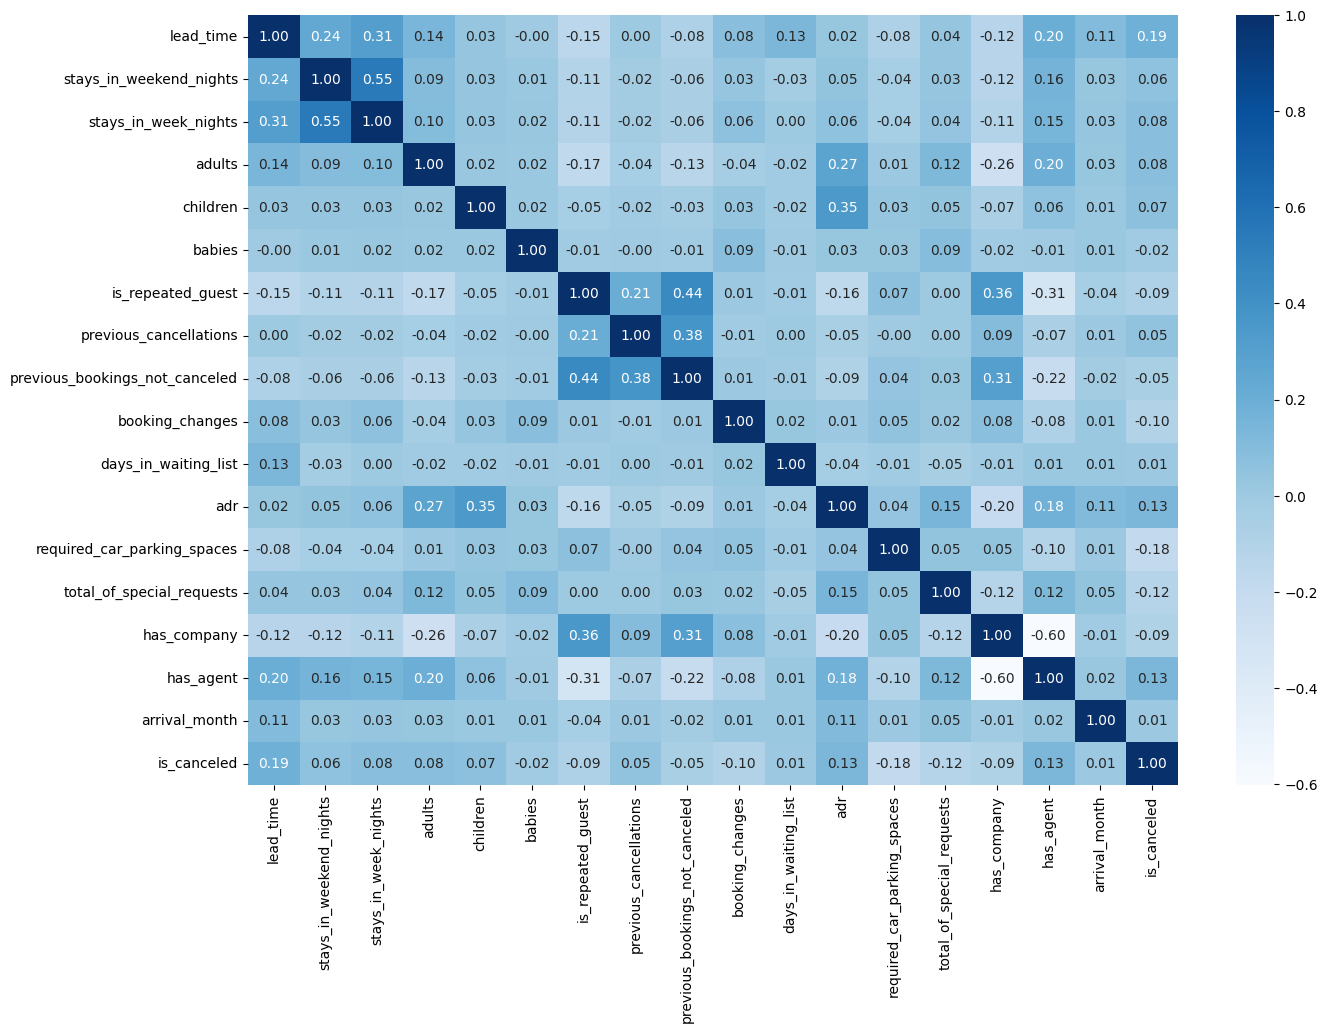

In [42]:
plt.figure(figsize=(15,10))
sns.heatmap(df_train.corr(numeric_only=True),annot=True,cmap='Blues',fmt='0.2f')
plt.show()

<Axes: xlabel='lead_time', ylabel='adr'>

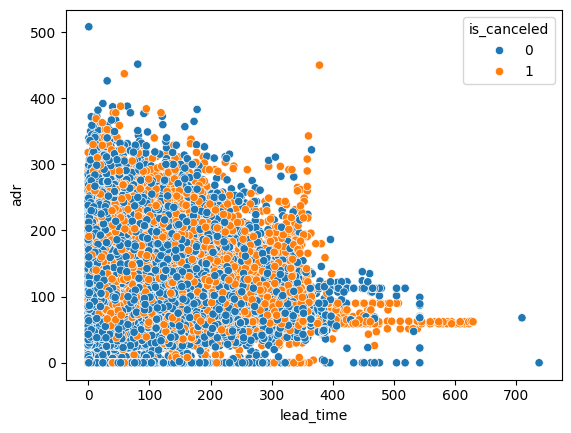

In [43]:
sns.scatterplot(data=df_train,x="lead_time",y="adr",hue="is_canceled")

In [44]:
df_train['country'].nunique()

173

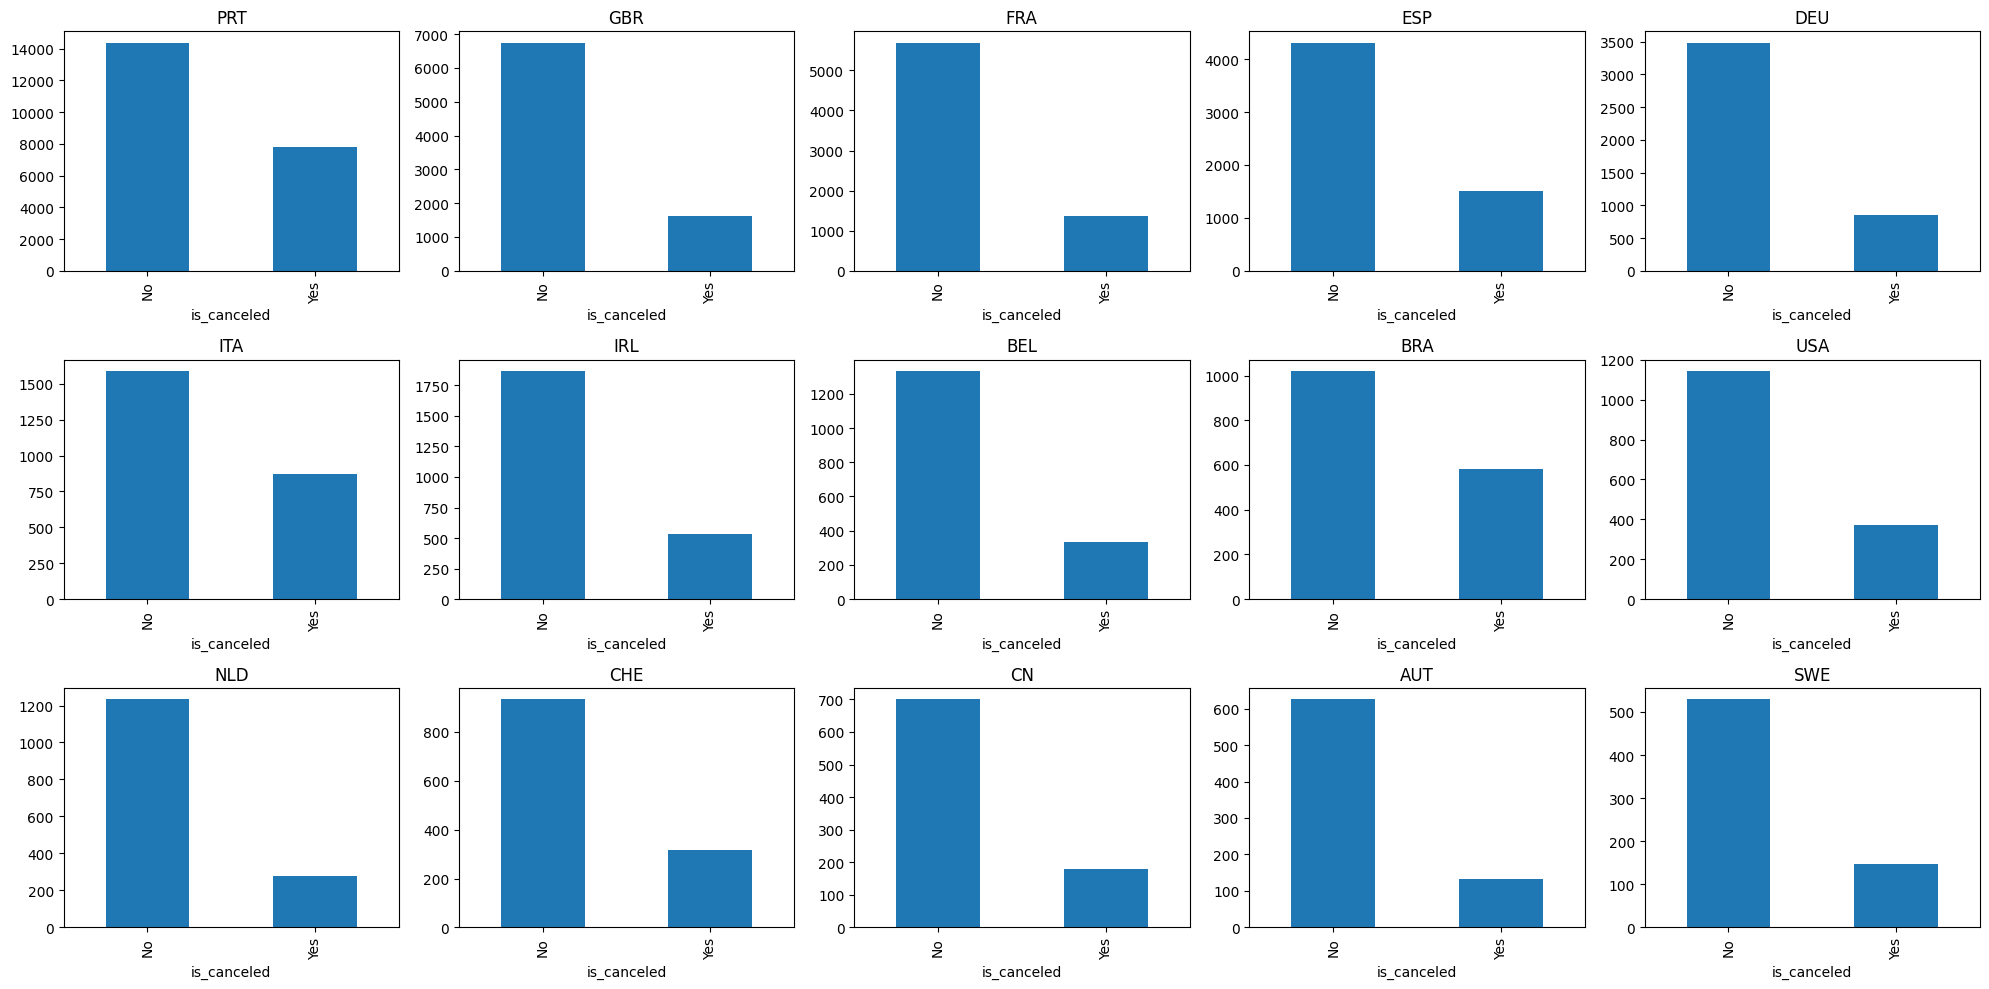

In [45]:
plt.figure(figsize=(20,10))
for n , c in enumerate(df_train['country'].value_counts().head(15).index):
    plt.subplot(3,5,n+1)
    df_train[df_train['country']==c]['is_canceled'].value_counts().reindex([0,1],fill_value=0).plot(kind = "bar")
    plt.title(c)
    plt.xticks([0,1],["No","Yes"])
    plt.tight_layout()

In [46]:
df_train['market_segment'].nunique()

8

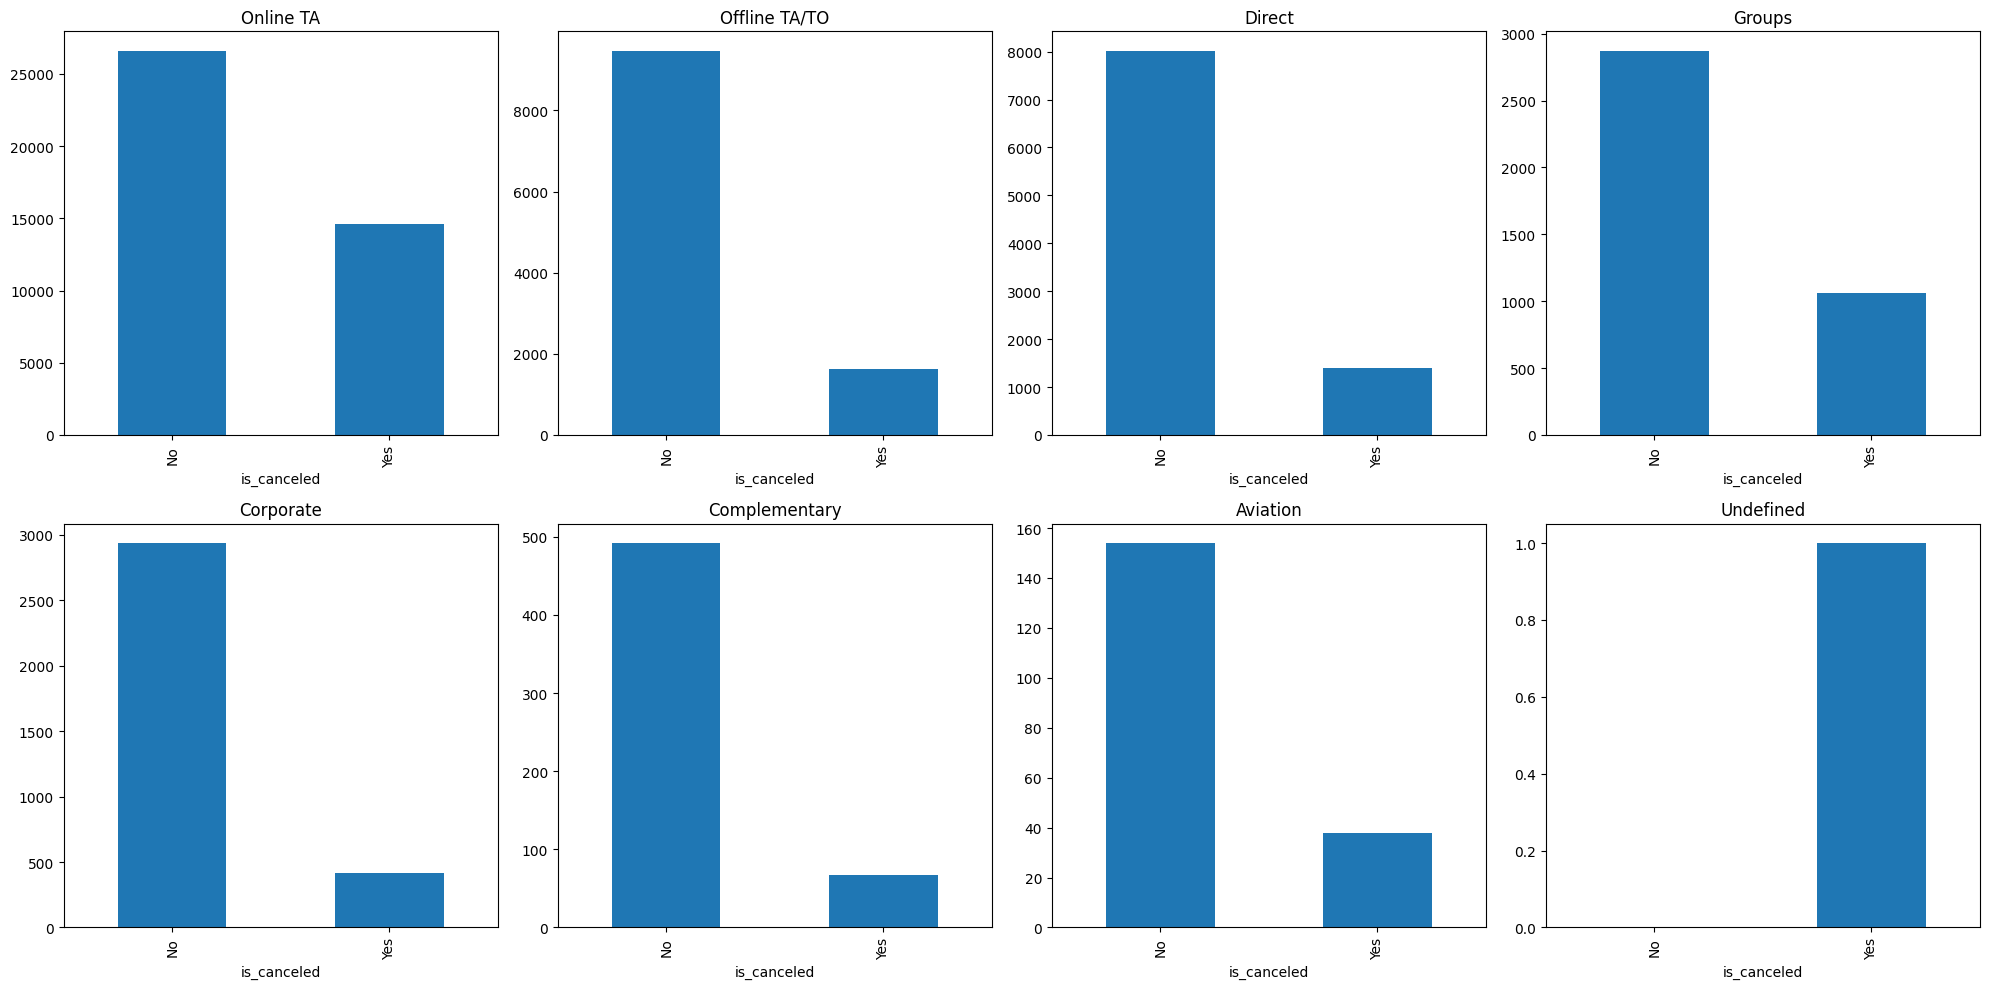

In [47]:
plt.figure(figsize=(20,10))
for n , c in enumerate(df_train['market_segment'].unique()):
    plt.subplot(2,4,n+1)
    df_train[df_train['market_segment']==c]['is_canceled'].value_counts().reindex([0,1],fill_value=0).plot(kind = "bar")
    plt.title(c)
    plt.xticks([0,1],["No","Yes"])
    plt.tight_layout()

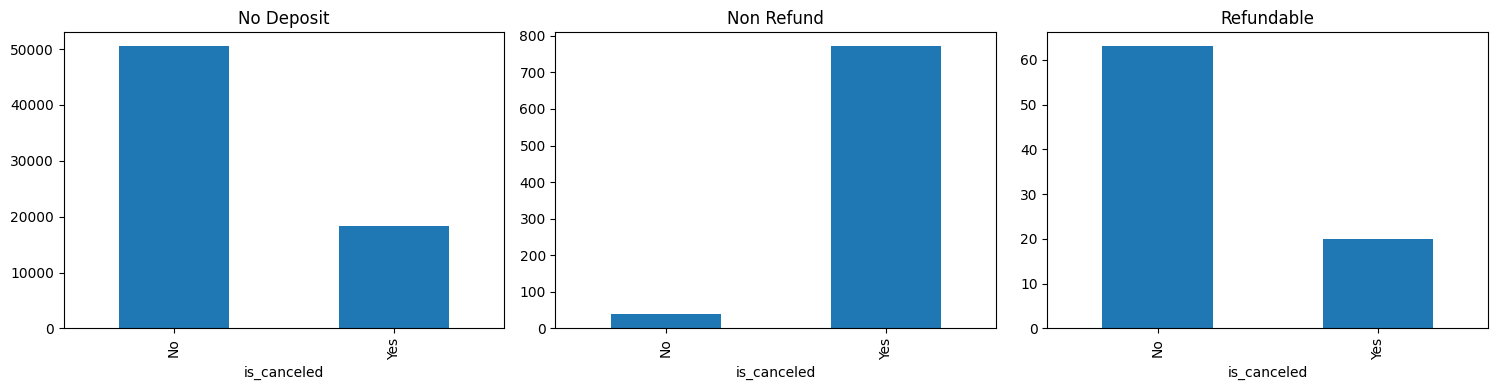

In [48]:
plt.figure(figsize=(20,4))
for n , c in enumerate(df_train['deposit_type'].unique()):
    plt.subplot(1,4,n+1)
    df_train[df_train['deposit_type']==c]['is_canceled'].value_counts().reindex([0,1],fill_value=0).plot(kind = "bar")
    plt.title(c)
    plt.xticks([0,1],["No","Yes"])
    plt.tight_layout()

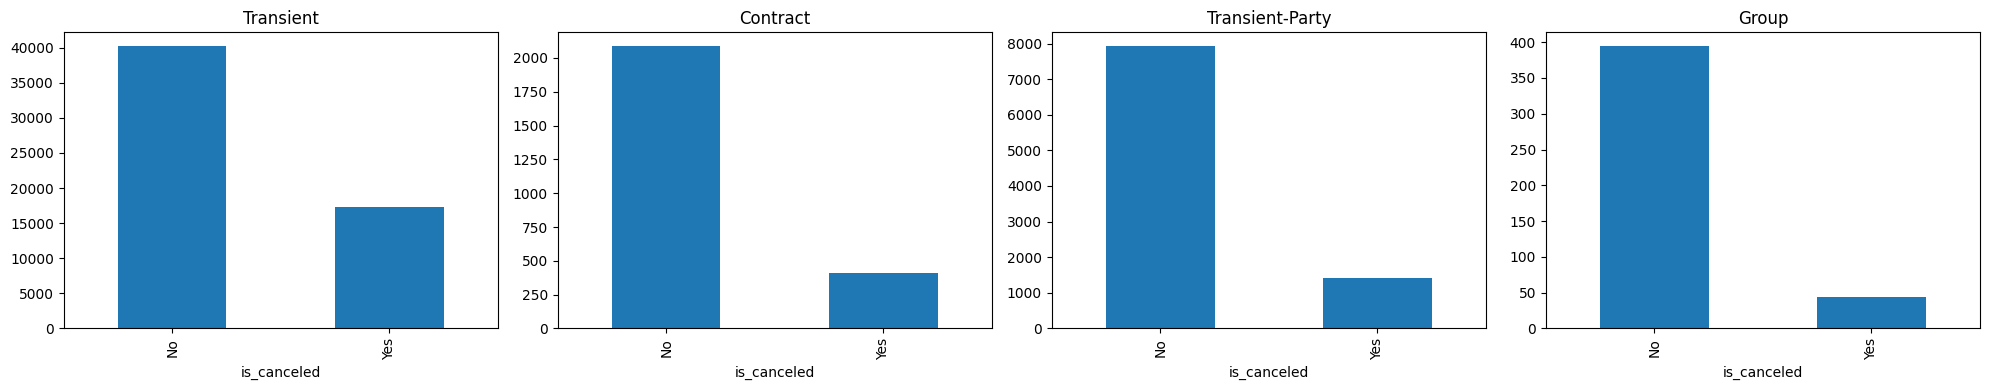

In [49]:
plt.figure(figsize=(20,4))
for n , c in enumerate(df_train['customer_type'].unique()):
    plt.subplot(1,4,n+1)
    df_train[df_train['customer_type']==c]['is_canceled'].value_counts().reindex([0,1],fill_value=0).plot(kind = "bar")
    plt.title(c)
    plt.xticks([0,1],["No","Yes"])
    plt.tight_layout()

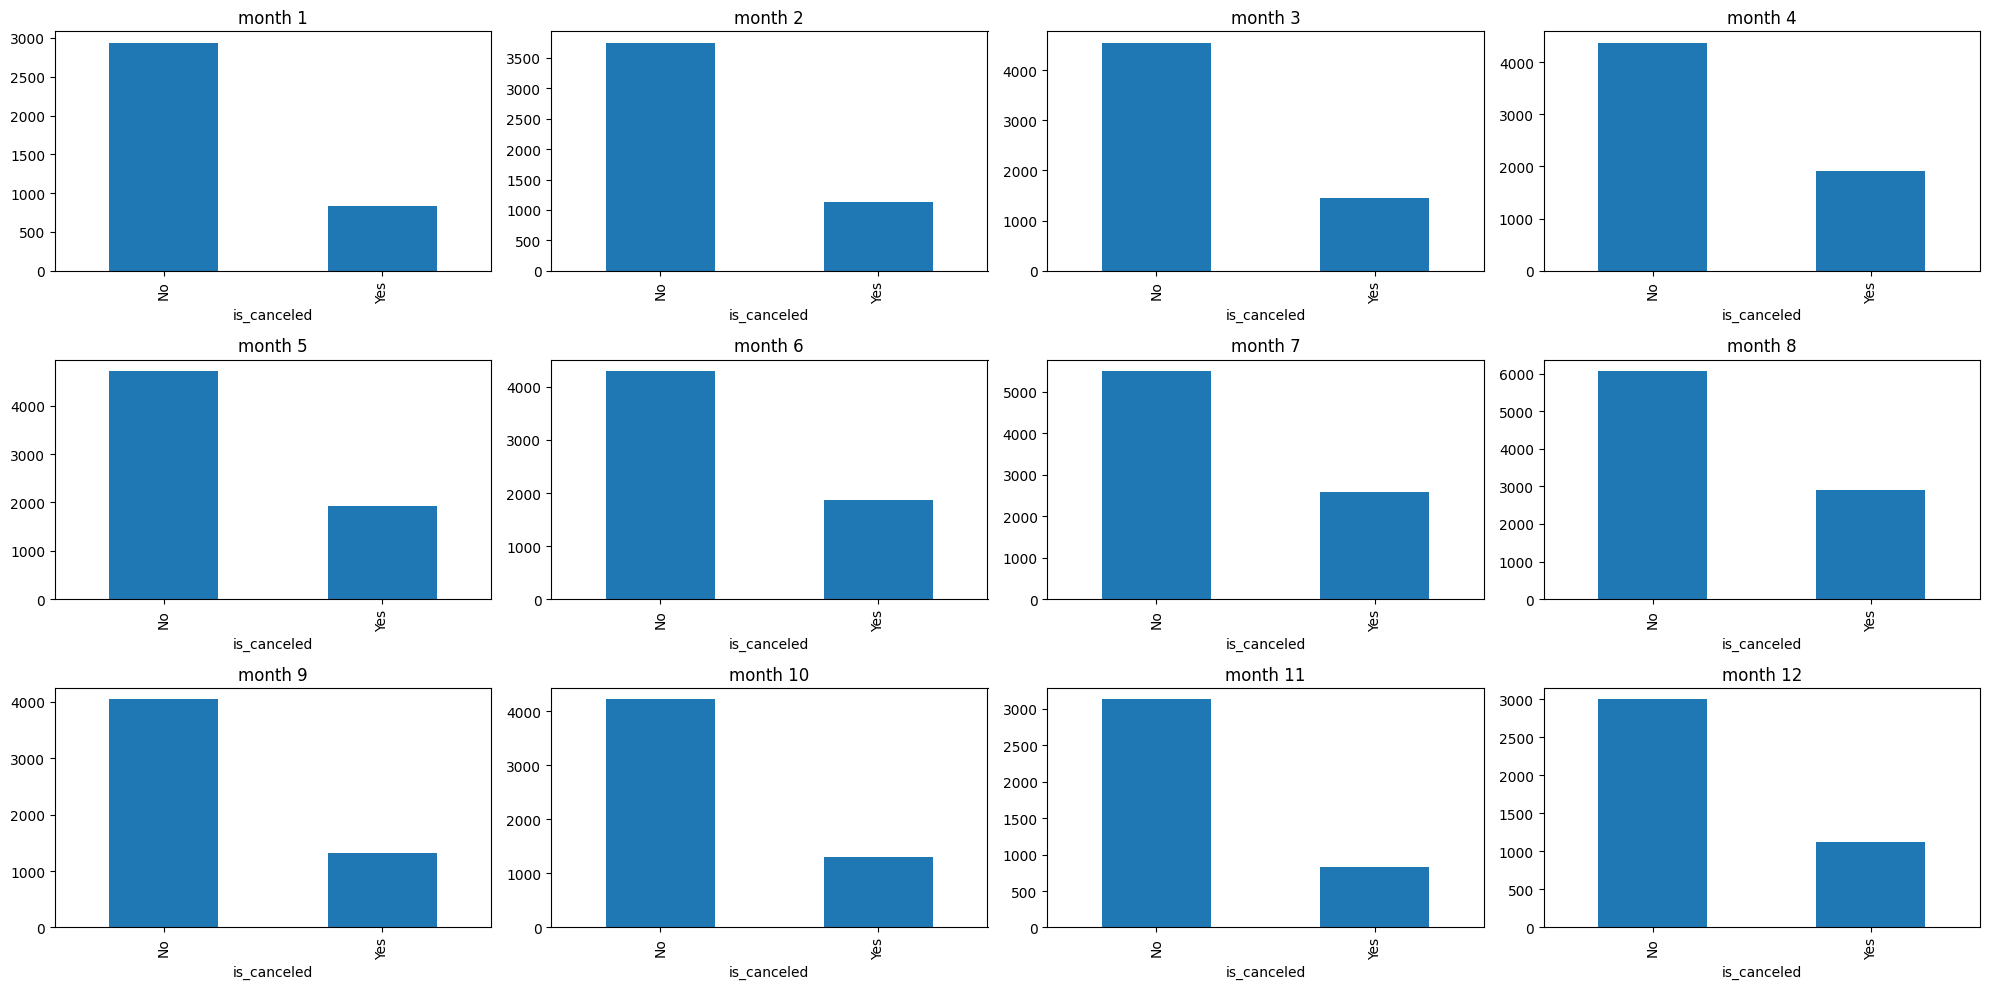

In [50]:
plt.figure(figsize=(20,10))
for n , c in enumerate(sorted(df_train['arrival_month'].unique())):
    plt.subplot(3,4,n+1)
    df_train[df_train['arrival_month']==c]['is_canceled'].value_counts().reindex([0,1],fill_value=0).plot(kind = "bar")
    plt.title("month " + str(c))
    plt.xticks([0,1],["No","Yes"])
    plt.tight_layout()

<Axes: xlabel='lead_time'>

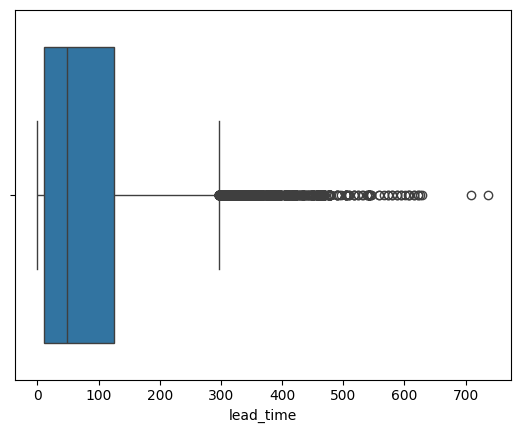

In [51]:
sns.boxplot(data =df_train ,x="lead_time")

<Axes: xlabel='adr'>

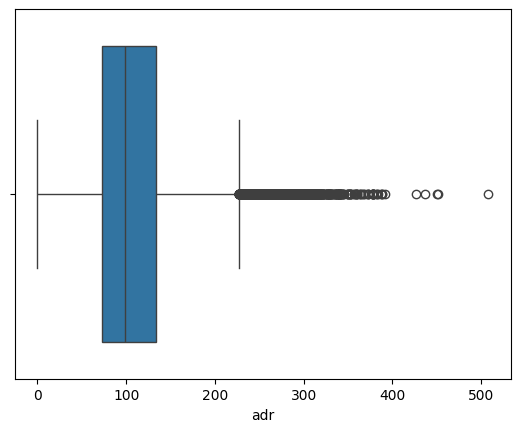

In [52]:
sns.boxplot(data =df_train ,x="adr")

In [53]:
df_train['adr'].median()

98.5

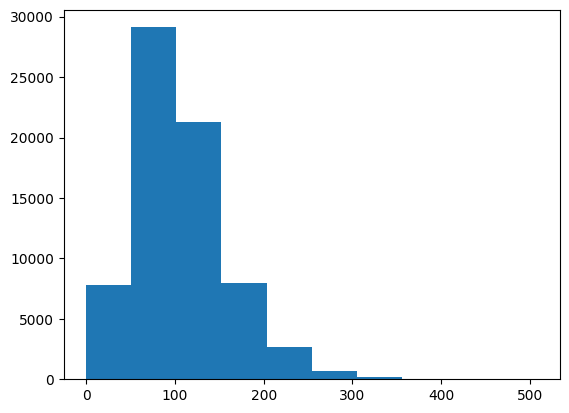

In [54]:
plt.hist(df_train["adr"] )
plt.show()

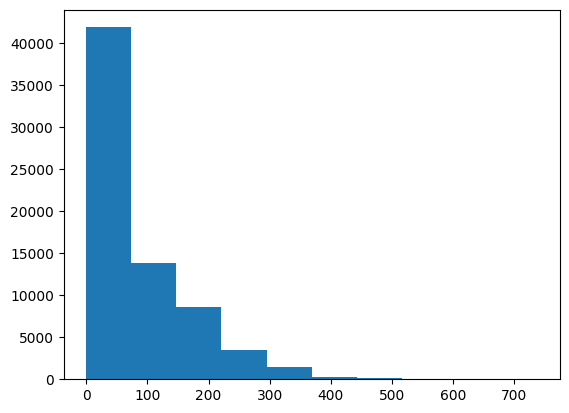

In [55]:
plt.hist(df_train["lead_time"] )
plt.show()

<Axes: xlabel='lead_time', ylabel='previous_cancellations'>

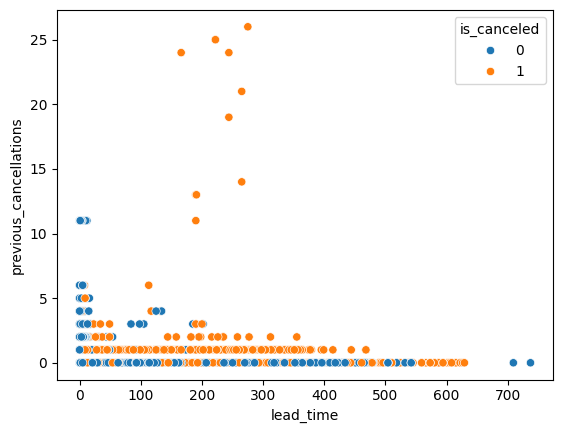

In [56]:
sns.scatterplot(data=df_train,x="lead_time",y="previous_cancellations",hue="is_canceled")

# Data Encoding

In [57]:
X_train.select_dtypes(include= 'object').columns

Index(['hotel', 'meal', 'country', 'market_segment', 'distribution_channel',
       'reserved_room_type', 'deposit_type', 'customer_type'],
      dtype='object')

In [58]:
X_train.select_dtypes(include= 'object').nunique()

,0
hotel,2
meal,4
country,173
market_segment,8
distribution_channel,5
reserved_room_type,9
deposit_type,3
customer_type,4


In [59]:
from sklearn.preprocessing import LabelEncoder , OrdinalEncoder , OneHotEncoder

In [60]:
lb = LabelEncoder()

In [61]:
X_train['hotel'] = lb.fit_transform(X_train['hotel'])

In [62]:
X_test['hotel'] = lb.transform(X_test['hotel'])

In [63]:
lb.classes_

array(['City Hotel', 'Resort Hotel'], dtype=object)

In [64]:
top_countries = X_train['country'].value_counts().head(10).index
top_countries

Index(['PRT', 'GBR', 'FRA', 'ESP', 'DEU', 'ITA', 'IRL', 'BEL', 'BRA', 'USA'], dtype='object', name='country')

In [65]:
X_train['country'] = X_train['country'].where(X_train['country'].isin(top_countries),'Other')
X_test['country'] = X_test['country'].where(X_test['country'].isin(top_countries),'Other')

In [66]:
cat_cols = ['meal','country','market_segment','distribution_channel','reserved_room_type','deposit_type','customer_type']

In [67]:
onehot = OneHotEncoder(handle_unknown='ignore')

In [68]:
onehot.fit(X_train[cat_cols])

OneHotEncoder(handle_unknown='ignore')

In [69]:
temp = onehot.transform(X_train[cat_cols]).toarray()
temp.shape

(69782, 44)

In [70]:
temp = pd.DataFrame(temp,columns=onehot.get_feature_names_out(cat_cols))

In [71]:
X_train = pd.concat([X_train,temp],axis=1)

In [72]:
X_train.drop(cat_cols,axis=1,inplace=True)

In [73]:
temp = onehot.transform(X_test[cat_cols]).toarray()
temp = pd.DataFrame(temp,columns=onehot.get_feature_names_out(cat_cols))

In [74]:
X_test = pd.concat([X_test,temp],axis=1)

In [75]:
X_test.drop(cat_cols,axis=1,inplace=True)

In [76]:
X_train.head()

,hotel,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,...,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,1,125,6,15,1,0.0,0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1,93,0,2,2,0.0,0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1,3,0,1,2,0.0,0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,175,0,4,2,0.0,0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1,16,2,4,1,0.0,0,0,1,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [77]:
X_train.shape , X_test.shape

((69782, 62), (17446, 62))

# Normalization (Scaling)

In [78]:
skew_cols = ['lead_time','adr','days_in_waiting_list','previous_cancellations','previous_bookings_not_canceled','booking_changes']
X_train[skew_cols].skew()

,0
lead_time,1.434638
adr,0.876631
days_in_waiting_list,19.696947
previous_cancellations,34.181713
previous_bookings_not_canceled,20.213001
booking_changes,5.048781


In [79]:
log_cols = ['lead_time','adr','days_in_waiting_list']
for col in log_cols:
  X_train[col] = np.log1p(X_train[col])
  X_test[col] = np.log1p(X_test[col])

In [80]:
X_train[log_cols].skew()

,0
lead_time,-0.715652
adr,-3.585887
days_in_waiting_list,10.761368


In [81]:
from sklearn.preprocessing import StandardScaler

In [82]:
scaler = StandardScaler()

In [83]:
scale_cols = ['lead_time','arrival_month','stays_in_weekend_nights','stays_in_week_nights','adults','children','babies',
              'previous_cancellations','previous_bookings_not_canceled','booking_changes',
              'days_in_waiting_list','adr','required_car_parking_spaces','total_of_special_requests']

In [84]:
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

In [85]:
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

In [86]:
X_train.head()

,hotel,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,...,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,1,0.803442,4.865554,6.085823,-1.473609,-0.305543,-0.093378,0,-0.080144,-0.10671,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1,0.623421,-0.977381,-0.305953,0.203600,-0.305543,-0.093378,0,-0.080144,-0.10671,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1,-1.316349,-0.977381,-0.797628,0.203600,-0.305543,-0.093378,0,-0.080144,-0.10671,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,1.008787,-0.977381,0.677397,0.203600,-0.305543,-0.093378,0,-0.080144,-0.10671,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1,-0.427312,0.970264,0.677397,-1.473609,-0.305543,-0.093378,0,2.464266,-0.10671,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [87]:
X_train.isnull().sum().sum() , X_test.isnull().sum().sum()

(np.int64(0), np.int64(0))

In [88]:
X_train.shape , X_test.shape

((69782, 62), (17446, 62))

In [89]:
list(X_train.columns) == list(X_test.columns)

True

# Build Machine Learning Model

### الموديلات المستخدمة وليه
| الموديل | سبب الاستخدام |
| --- | --- |
| Logistic Regression | موديل خطي بسيط، نقطة بداية (Baseline) وسهل التفسير. |
| KNN | بيقارن الحجز بأقرب الحجوزات ليه، حساس للـ Scaling (وإحنا عملنا Scaling). |
| Naive Bayes | سريع جدًا وبيفترض إن الأعمدة مستقلة (افتراض ضعيف هنا). |
| SVM | بيدور على أحسن فاصل بين الفئتين، بطيء على داتا كبيرة فبنستخدم عينة. |
| Decision Tree | قواعد if/else واضحة وسهلة الشرح، لكن بيعمل Overfitting بسهولة. |
| Random Forest / Extra Trees / Bagging | مجموعة أشجار بتقلل الـ Overfitting. |
| AdaBoost / Gradient Boosting / HistGB / XGBoost / LightGBM / CatBoost | Boosting: كل شجرة بتصلح أخطاء اللي قبلها، وغالبًا الأقوى على الداتا الجدولية. |
| Voting / Stacking | بيجمعوا أكتر من موديل. |

**موديلات مستبعدة:** `Linear Regression` و`Lasso` و`Ridge` و`ElasticNet` و`SVR` و`KNN Regressor` كلها للـ Regression، ومشكلتنا Classification.
وبديلهم هنا Logistic Regression (وفيه `C` بيتحكم في الـ Regularization).

In [90]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 24.5 MB/s  0:00:03m0:00:0100:01


In [91]:
from tqdm import tqdm
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import VotingClassifier, StackingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import average_precision_score, confusion_matrix, classification_report
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

In [92]:
models ={
    "Logistic Regression":LogisticRegression(max_iter=1000),
    "KNN":KNeighborsClassifier(n_neighbors=5,metric='minkowski',p=1),
    "Naive Bayes":GaussianNB(),
    "SVM":SVC(kernel='rbf', C=1),
    "Decision Tree":DecisionTreeClassifier(criterion='gini',max_depth=10,random_state=42),
    "Random Forest":RandomForestClassifier(n_estimators=50,criterion='gini',max_depth=10,random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, random_state=42),
    "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(criterion='gini',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostClassifier(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

In [93]:
def classification_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X)[:,1]
    else:
        y_score = model.decision_function(X)
    Accuracy = accuracy_score(y_actual, y_pred)
    Precision = precision_score(y_actual, y_pred)
    Recall = recall_score(y_actual, y_pred)
    F1 = f1_score(y_actual, y_pred)
    AUC = roc_auc_score(y_actual, y_score)
    return Accuracy, Precision, Recall, F1, AUC

In [94]:
errors={}
for model_name , model in tqdm(models.items()):
    if model_name in ['SVM','KNN']:
        X_fit , y_fit = X_train[:20000] , y_train[:20000]
    else:
        X_fit , y_fit = X_train , y_train

    model.fit(X_fit,y_fit)
    Acc_Train, Pre_Train, Rec_Train, F1_Train, AUC_Train = classification_metrics(model, X_fit, y_fit)
    Acc_Test, Pre_Test, Rec_Test, F1_Test, AUC_Test = classification_metrics(model, X_test, y_test)

    errors[model_name] = {
        "Accuracy Train":Acc_Train,
        "Accuracy Test":Acc_Test,
        "Precision Train":Pre_Train,
        "Precision Test":Pre_Test,
        "Recall Train":Rec_Train,
        "Recall Test":Rec_Test,
        "F1 Train":F1_Train,
        "F1 Test":F1_Test,
        "ROC AUC Train":AUC_Train,
        "ROC AUC Test":AUC_Test
    }

100%|██████████| 14/14 [03:23<00:00, 14.51s/it]


### Voting

In [95]:
clf1 = LogisticRegression(max_iter=1000)
clf2 = RandomForestClassifier(n_estimators=50, random_state=1)
clf3 = DecisionTreeClassifier(random_state=1)


voting1 = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft')


voting2 = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], voting='soft', weights=[2, 2, 1])

voting1.fit(X_train, y_train)
voting2.fit(X_train, y_train)

VotingClassifier(estimators=[('lr', LogisticRegression(max_iter=1000)),
                             ('rf',
                              RandomForestClassifier(n_estimators=50,
                                                     random_state=1)),
                             ('dt', DecisionTreeClassifier(random_state=1))],
                 voting='soft', weights=[2, 2, 1])

In [96]:
for name , model in [("Simple Voting",voting1),("Weighted Voting",voting2)]:
    Acc_Train, Pre_Train, Rec_Train, F1_Train, AUC_Train = classification_metrics(model, X_train, y_train)
    Acc_Test, Pre_Test, Rec_Test, F1_Test, AUC_Test = classification_metrics(model, X_test, y_test)

    errors[name] = {
        "Accuracy Train":Acc_Train,
        "Accuracy Test":Acc_Test,
        "Precision Train":Pre_Train,
        "Precision Test":Pre_Test,
        "Recall Train":Rec_Train,
        "Recall Test":Rec_Test,
        "F1 Train":F1_Train,
        "F1 Test":F1_Test,
        "ROC AUC Train":AUC_Train,
        "ROC AUC Test":AUC_Test
    }

In [97]:
classifiers = [
    ('rf', RandomForestClassifier(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostClassifier(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMClassifier(n_estimators=50, learning_rate=0.1, random_state=42, verbose=-1))
]

meta_classifier = XGBClassifier()

stacking_classifier = StackingClassifier(
    estimators=classifiers,
    final_estimator=meta_classifier,
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_classifier.fit(X_train, y_train)

StackingClassifier(cv=5,
                   estimators=[('rf',
                                RandomForestClassifier(n_estimators=50,
                                                       random_state=42)),
                               ('gb',
                                GradientBoostingClassifier(n_estimators=50,
                                                           random_state=42)),
                               ('cat',
                                CatBoostClassifier(iterations=50, learning_rate=0.1, verbose=0)),
                               ('lgb',
                                LGBMClassifier(n_estimators=50, random_state=42,
                                               verbose=-1))],
                   final_estimator=XGBClassifier(base_score=None,...
                                                 gamma=None, grow_policy=None,
                                                 importance_type=None,
                                                 interaction_constraints=None,
                                                 learning_rate=None,
                                                 max_bin=None,
                                                 max_cat_threshold=None,
                                                 max_cat_to_onehot=None,
                                                 max_delta_step=None,
                                                 max_depth=None,
                                                 max_leaves=None,
                                                 min_child_weight=None,
                                                 missing=nan,
                                                 monotone_constraints=None,
                                                 multi_strategy=None,
                                                 n_estimators=None, n_jobs=None,
                                                 num_parallel_tree=None, ...),
                   n_jobs=-1, passthrough=True)

In [98]:
Acc_Train, Pre_Train, Rec_Train, F1_Train, AUC_Train = classification_metrics(stacking_classifier, X_train, y_train)
Acc_Test, Pre_Test, Rec_Test, F1_Test, AUC_Test = classification_metrics(stacking_classifier, X_test, y_test)

errors["Stacking"] = {
    "Accuracy Train":Acc_Train,
    "Accuracy Test":Acc_Test,
    "Precision Train":Pre_Train,
    "Precision Test":Pre_Test,
    "Recall Train":Rec_Train,
    "Recall Test":Rec_Test,
    "F1 Train":F1_Train,
    "F1 Test":F1_Test,
    "ROC AUC Train":AUC_Train,
    "ROC AUC Test":AUC_Test
}

In [99]:
all_models = dict(models)
all_models["Simple Voting"] = voting1
all_models["Weighted Voting"] = voting2
all_models["Stacking"] = stacking_classifier

# Models Comparison (Before Tuning)

In [100]:
errors_df = pd.DataFrame(errors).T
errors_df

,Accuracy Train,Accuracy Test,Precision Train,Precision Test,Recall Train,Recall Test,F1 Train,F1 Test,ROC AUC Train,ROC AUC Test
Logistic Regression,0.795105,0.797203,0.679859,0.683721,0.482974,0.489796,0.564749,0.570735,0.842022,0.846418
KNN,0.852850,0.787057,0.761170,0.627313,0.679601,0.557684,0.718076,0.590453,0.913711,0.809910
Naive Bayes,0.707403,0.710363,0.477587,0.481410,0.672342,0.676801,0.558472,0.562624,0.755492,0.758932
SVM,0.820450,0.817322,0.744535,0.735354,0.531097,0.525406,0.619960,0.612899,0.877341,0.865182
Decision Tree,0.821301,0.814112,0.718616,0.699106,0.576434,0.569971,0.639720,0.627968,0.873916,0.864598
Random Forest,0.805695,0.807807,0.760543,0.767048,0.429137,0.433361,0.548680,0.553826,0.873217,0.867885
ExtraTrees,0.996561,0.819214,0.999053,0.703557,0.988441,0.593086,0.993719,0.643616,0.999969,0.870067
Bagging,0.824797,0.820245,0.725978,0.713262,0.583776,0.580175,0.647157,0.639871,0.885647,0.876185
AdaBoost,0.775974,0.777771,0.625695,0.626608,0.463032,0.476676,0.532212,0.541455,0.806084,0.807890
GradientBoosting,0.814350,0.814227,0.718307,0.715192,0.535458,0.540192,0.613549,0.615494,0.869856,0.872225


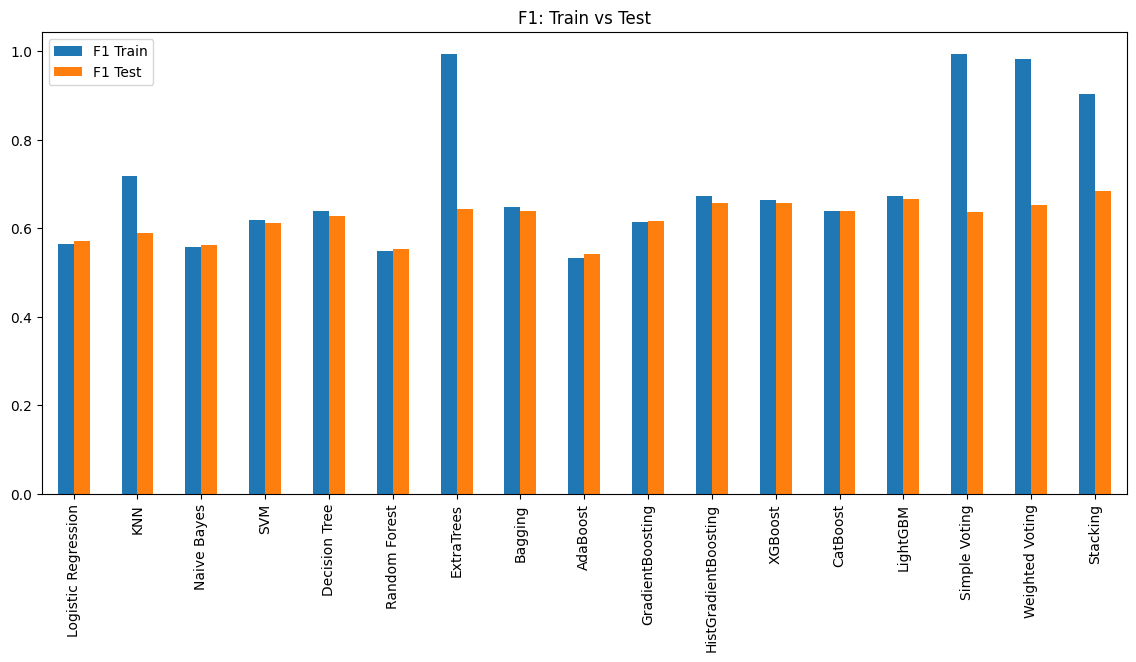

In [101]:
errors_df[["F1 Train", "F1 Test"]].plot.bar(figsize=(14,6))
plt.title("F1: Train vs Test")
plt.show()

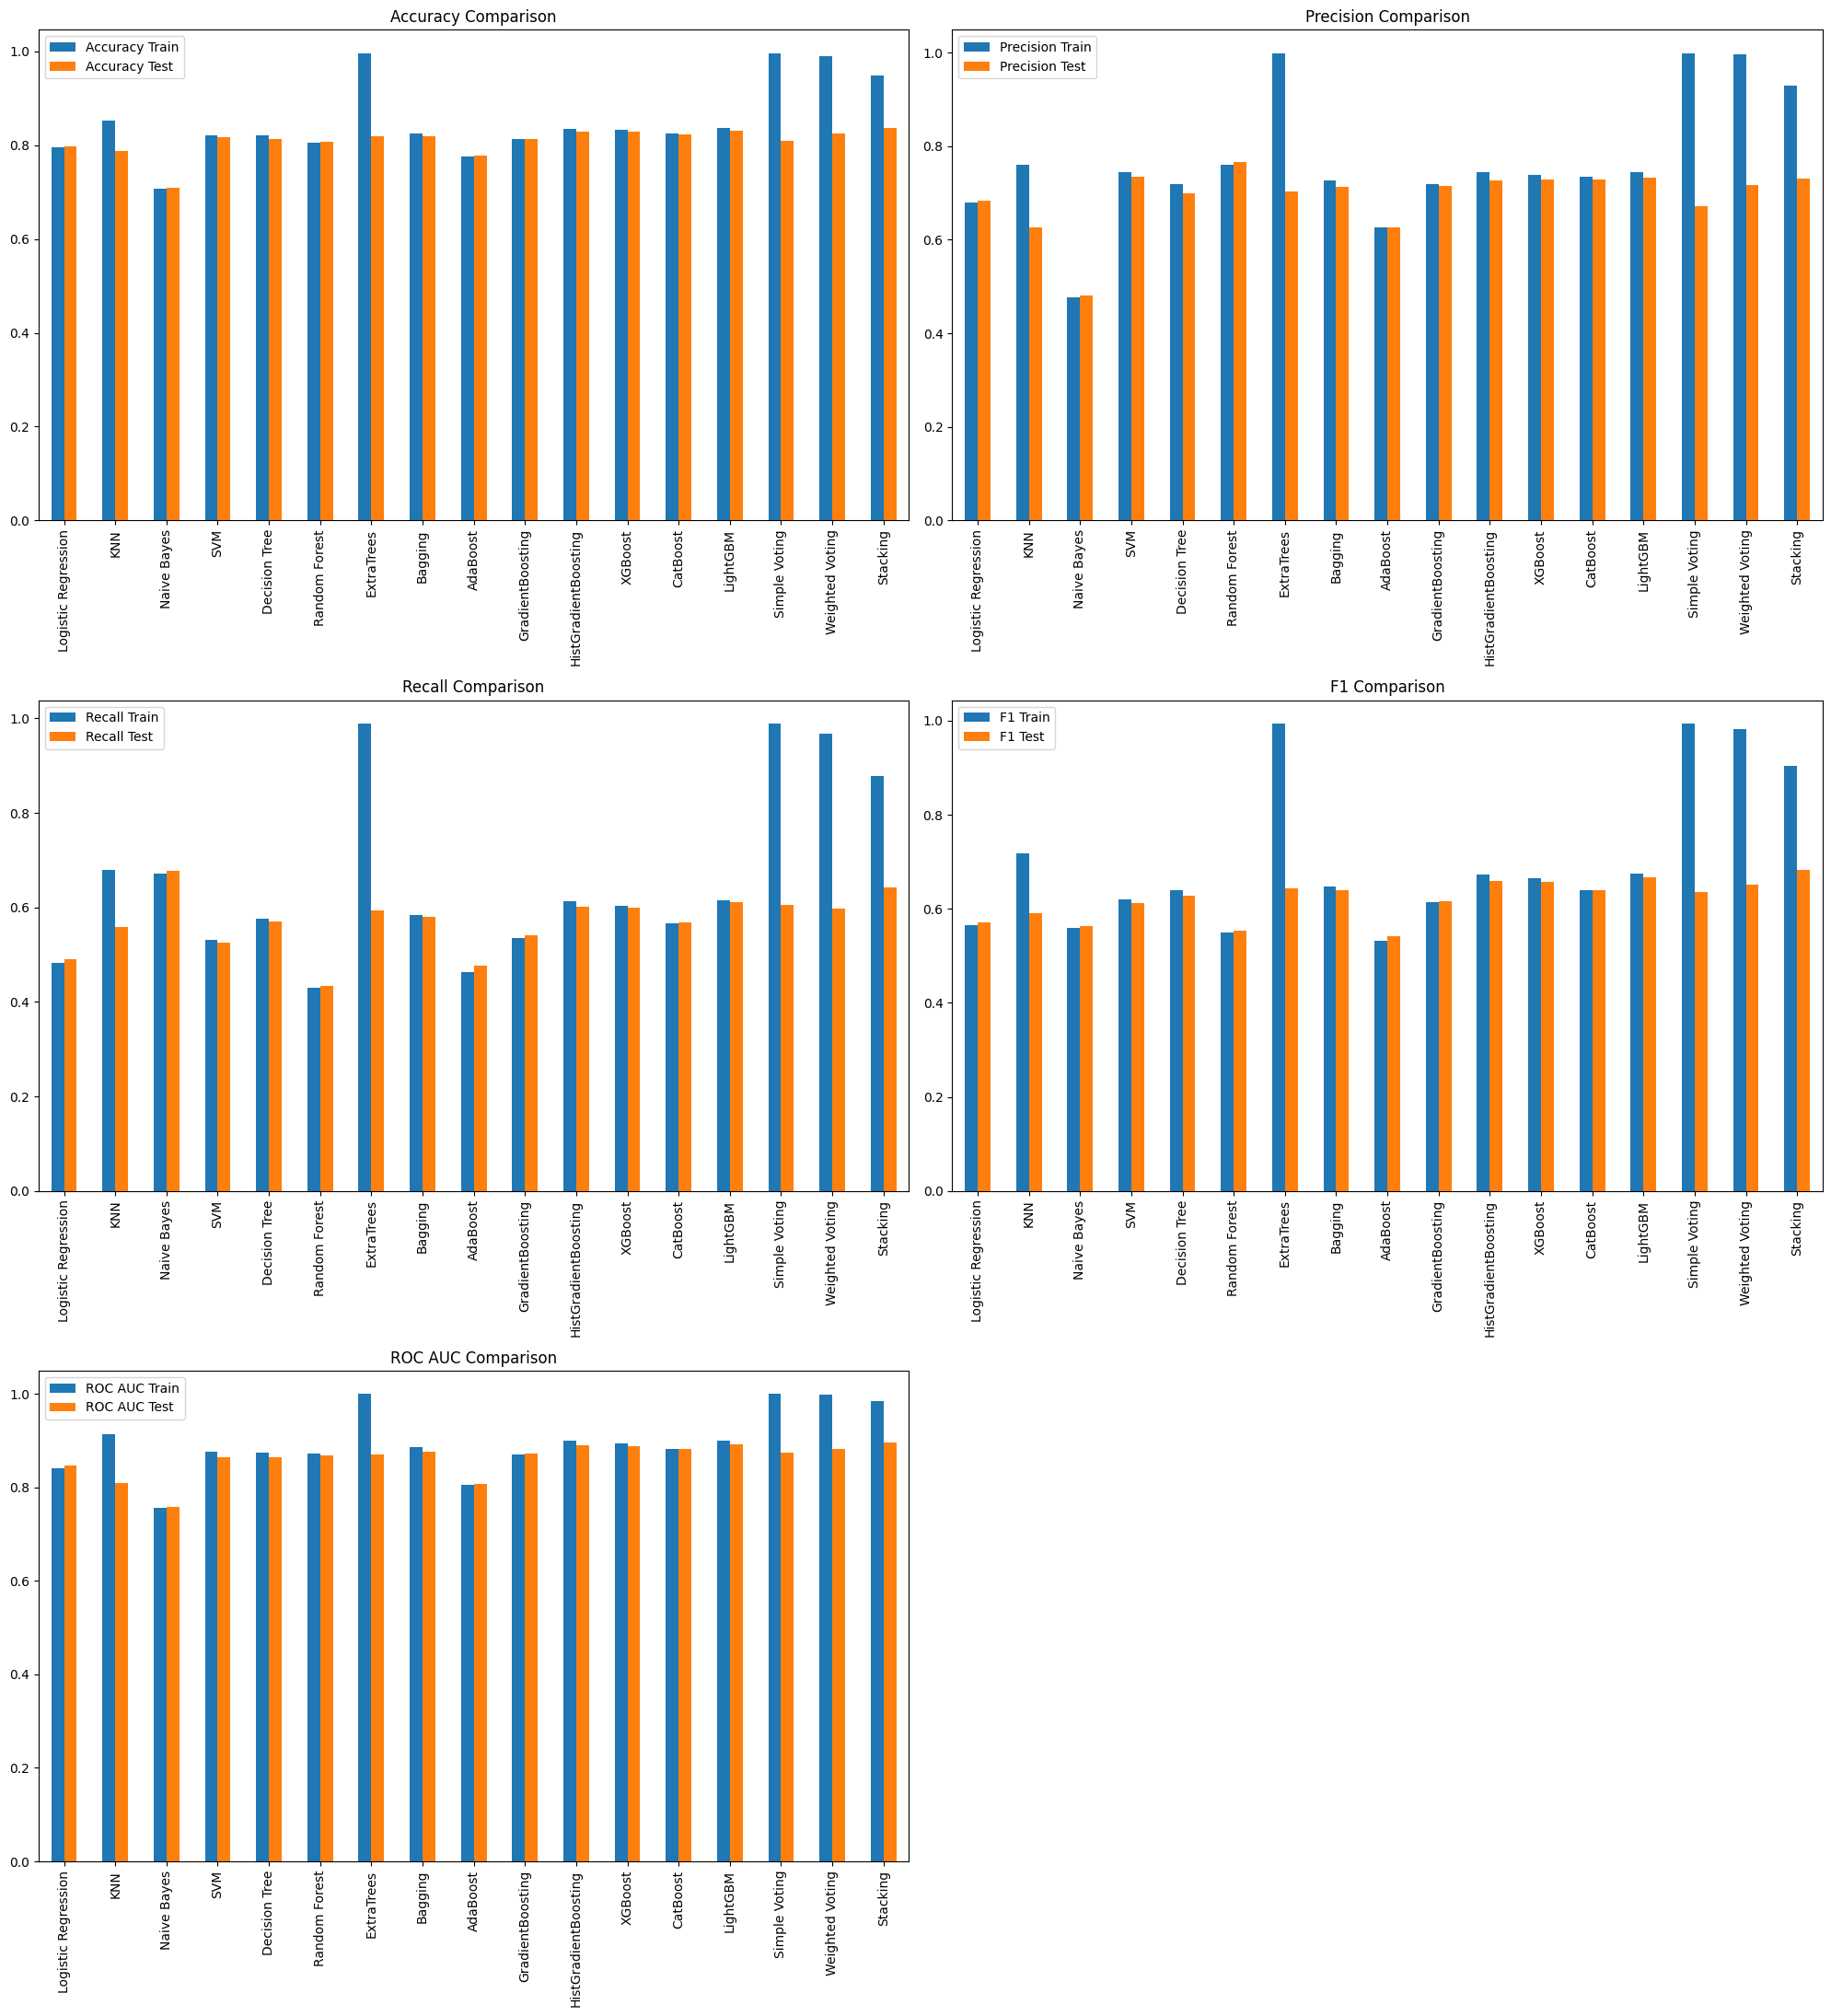

In [102]:
cols = [
    ['Accuracy Train', 'Accuracy Test'],
    ['Precision Train', 'Precision Test'],
    ['Recall Train', 'Recall Test'],
    ['F1 Train', 'F1 Test'],
    ['ROC AUC Train', 'ROC AUC Test']
]

plt.figure(figsize=(20,22))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].replace(" Train","") + ' Comparison')

plt.tight_layout()
plt.show()

In [103]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

In [104]:
SKIP_CV = ['Stacking']
cv_results = {}

for model_name , model in tqdm(all_models.items()):
    if model_name in SKIP_CV:
        continue
    if model_name in ['SVM','KNN']:
        X_cv , y_cv = X_train[:20000] , y_train[:20000]
    else:
        X_cv , y_cv = X_train , y_train

    scores = cross_validate(model, X_cv, y_cv, cv=skf, scoring=['f1','roc_auc'], n_jobs=-1)

    cv_results[model_name] = {
        "CV F1 mean":scores['test_f1'].mean(),
        "CV F1 std":scores['test_f1'].std(),
        "CV AUC mean":scores['test_roc_auc'].mean(),
        "CV AUC std":scores['test_roc_auc'].std()
    }

100%|██████████| 17/17 [02:59<00:00, 10.57s/it]


In [105]:
cv_df = pd.DataFrame(cv_results).T.sort_values(by="CV F1 mean",ascending=False)
cv_df

,CV F1 mean,CV F1 std,CV AUC mean,CV AUC std
LightGBM,0.654325,0.001778,0.886050,0.000141
HistGradientBoosting,0.651596,0.000917,0.885166,0.000249
XGBoost,0.644784,0.001900,0.881972,0.000776
Weighted Voting,0.634375,0.003954,0.873198,0.001009
ExtraTrees,0.634286,0.002565,0.863900,0.002041
CatBoost,0.632211,0.003397,0.876792,0.000714
Bagging,0.630272,0.003072,0.870738,0.000892
Decision Tree,0.620215,0.004647,0.854666,0.001054
Simple Voting,0.616294,0.001341,0.864848,0.001030
GradientBoosting,0.609434,0.000708,0.867082,0.001320


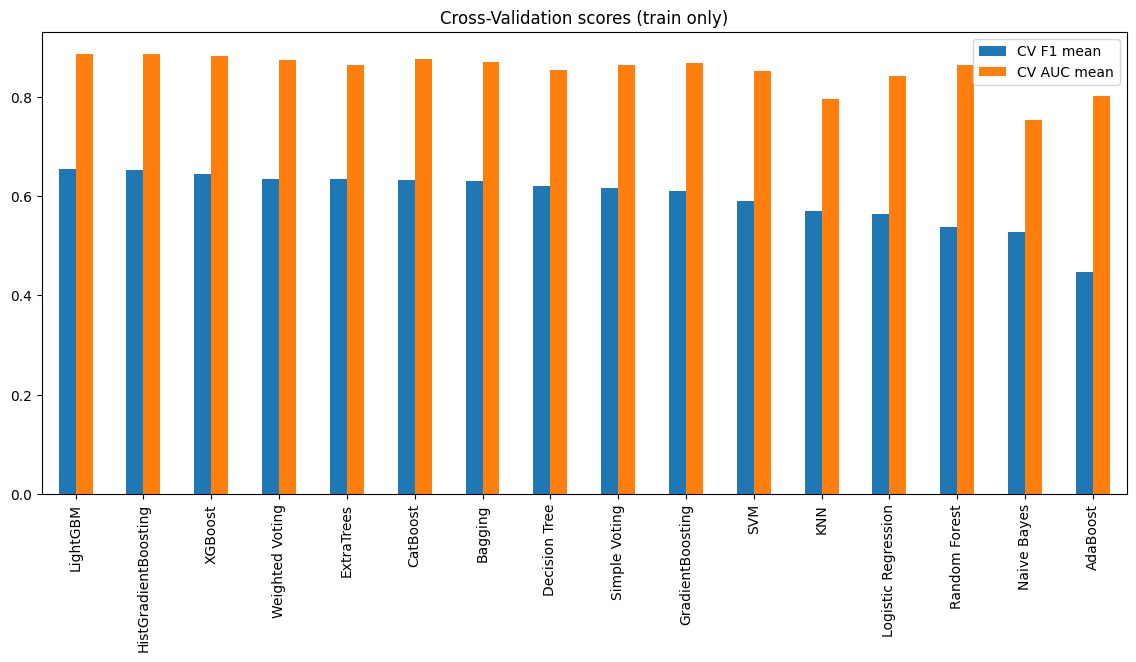

In [106]:
cv_df[["CV F1 mean","CV AUC mean"]].plot.bar(figsize=(14,6))
plt.title("Cross-Validation scores (train only)")
plt.show()

# GridSearchCV


In [107]:
param_grids = {
    "Logistic Regression": {"C":[0.01,0.1,1,10]},
    "KNN": {"n_neighbors":[3,5,11],"weights":["uniform","distance"]},
    "Naive Bayes": {"var_smoothing":[1e-9,1e-7,1e-5]},
    "SVM": {"C":[1,10]},
    "Decision Tree": {"max_depth":[5,10,15,20],"min_samples_leaf":[1,10,50]},
    "Random Forest": {"n_estimators":[50,100],"max_depth":[10,20],"min_samples_leaf":[1,5]},
    "ExtraTrees": {"n_estimators":[100,200],"max_depth":[None,20]},
    "Bagging": {"n_estimators":[50,100]},
    "AdaBoost": {"n_estimators":[15,50,100],"learning_rate":[0.1,1]},
    "GradientBoosting": {"n_estimators":[100,200],"max_depth":[3,5]},
    "HistGradientBoosting": {"max_iter":[100,300],"learning_rate":[0.05,0.1]},
    "XGBoost": {"n_estimators":[100,300],"learning_rate":[0.05,0.1],"max_depth":[4,6]},
    "CatBoost": {"iterations":[100,300],"depth":[4,6]},
    "LightGBM": {"n_estimators":[100,300],"learning_rate":[0.05,0.1],"num_leaves":[31,63]}
}

In [108]:
candidates = [name for name in cv_df.index if name in param_grids][:3]
candidates

['LightGBM', 'HistGradientBoosting', 'XGBoost']

In [109]:
grids = {}
grid_rows = {}

for name in candidates:
    if name in ['SVM','KNN']:
        X_g , y_g = X_train[:20000] , y_train[:20000]
    else:
        X_g , y_g = X_train , y_train

    grid = GridSearchCV(estimator=all_models[name], param_grid=param_grids[name],
                        cv=skf, scoring='f1', n_jobs=-1)
    grid.fit(X_g, y_g)
    grids[name] = grid

    print(name)
    print("best_params_ :", grid.best_params_)
    print("best_score_  :", round(grid.best_score_,4))
    print()

    grid_rows[name] = {
        "CV F1 before":cv_df.loc[name,"CV F1 mean"],
        "CV F1 after (best_score_)":grid.best_score_,
        "best_params":grid.best_params_
    }

LightGBM
best_params_ : {'learning_rate': 0.1, 'n_estimators': 300, 'num_leaves': 63}
best_score_  : 0.6677

HistGradientBoosting
best_params_ : {'learning_rate': 0.1, 'max_iter': 300}
best_score_  : 0.6578

XGBoost
best_params_ : {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300}
best_score_  : 0.6626



In [110]:
grid_df = pd.DataFrame(grid_rows).T
grid_df["Improvement"] = grid_df["CV F1 after (best_score_)"] - grid_df["CV F1 before"]
grid_df

,CV F1 before,CV F1 after (best_score_),best_params,Improvement
LightGBM,0.654325,0.667686,"{'learning_rate': 0.1, 'n_estimators': 300, 'n...",0.013361
HistGradientBoosting,0.651596,0.657782,"{'learning_rate': 0.1, 'max_iter': 300}",0.006186
XGBoost,0.644784,0.662642,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.017857


In [111]:
best_name = grid_df["CV F1 after (best_score_)"].astype(float).idxmax()
best_name

'LightGBM'

In [112]:
best_params = grids[best_name].best_params_
best_params

{'learning_rate': 0.1, 'n_estimators': 300, 'num_leaves': 63}

In [113]:
best_tuned = grids[best_name].best_estimator_
best_default = all_models[best_name]

# Final Evaluation on Test Set

In [114]:
rows = {}
for label , m in [("Before tuning",best_default),("After tuning",best_tuned)]:
    Acc, Pre, Rec, F1, AUC = classification_metrics(m, X_test, y_test)
    rows[label] = {"Accuracy":Acc,"Precision":Pre,"Recall":Rec,"F1":F1,"ROC AUC":AUC}

final_df = pd.DataFrame(rows).T
final_df

,Accuracy,Precision,Recall,F1,ROC AUC
Before tuning,0.831537,0.732817,0.610579,0.666137,0.892825
After tuning,0.834919,0.729137,0.636818,0.679858,0.899343


In [115]:
y_pred = best_tuned.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['kept','canceled']))

              precision    recall  f1-score   support

        kept       0.87      0.91      0.89     12644
    canceled       0.73      0.64      0.68      4802

    accuracy                           0.83     17446
   macro avg       0.80      0.77      0.78     17446
weighted avg       0.83      0.83      0.83     17446



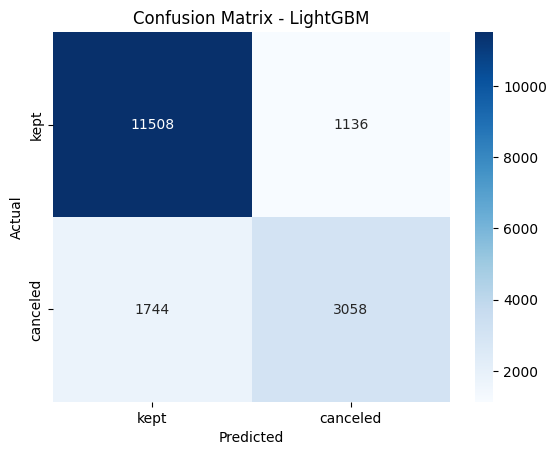

In [116]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
            xticklabels=["kept","canceled"],yticklabels=["kept","canceled"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - " + best_name)
plt.show()

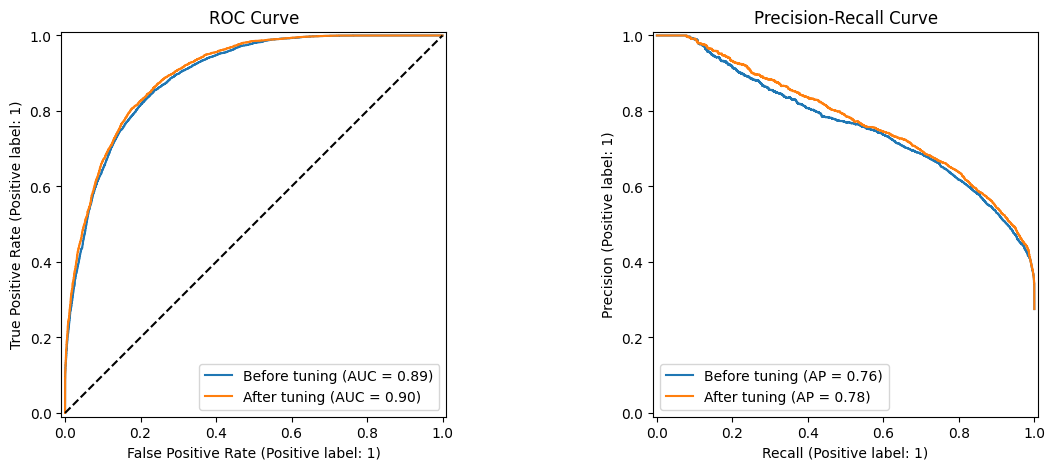

In [117]:
fig , ax = plt.subplots(1,2,figsize=(14,5))

RocCurveDisplay.from_estimator(best_default, X_test, y_test, name="Before tuning", ax=ax[0])
RocCurveDisplay.from_estimator(best_tuned, X_test, y_test, name="After tuning", ax=ax[0])
ax[0].plot([0,1],[0,1],"k--")
ax[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_estimator(best_default, X_test, y_test, name="Before tuning", ax=ax[1])
PrecisionRecallDisplay.from_estimator(best_tuned, X_test, y_test, name="After tuning", ax=ax[1])
ax[1].set_title("Precision-Recall Curve")

plt.show()

In [118]:
if hasattr(best_tuned, "predict_proba"):
    y_score = best_tuned.predict_proba(X_test)[:,1]
else:
    y_score = best_tuned.decision_function(X_test)

print("ROC AUC :", round(roc_auc_score(y_test, y_score),4))
print("Average Precision (AP) :", round(average_precision_score(y_test, y_score),4))
print("Baseline AP (share of canceled) :", round(y_test.mean(),4))

ROC AUC : 0.8993
Average Precision (AP) : 0.7764
Baseline AP (share of canceled) : 0.2752


### Feature Importance

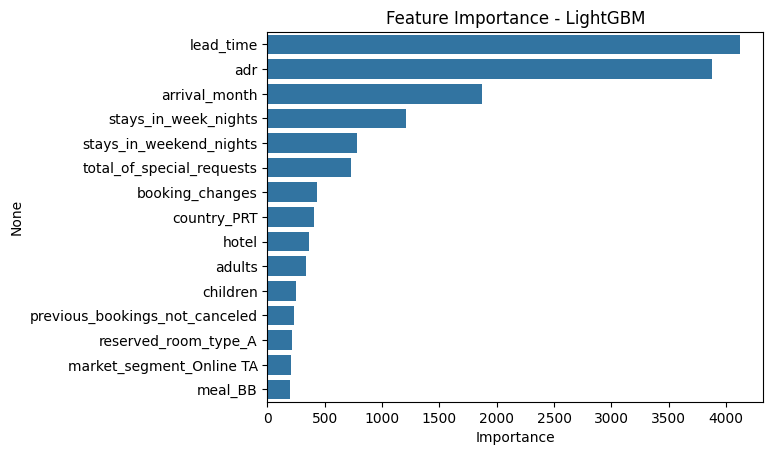

In [119]:
if hasattr(best_tuned, "feature_importances_"):
    imp = pd.Series(best_tuned.feature_importances_,index=X_train.columns)
elif hasattr(best_tuned, "coef_"):
    imp = pd.Series(np.abs(best_tuned.coef_[0]),index=X_train.columns)
else:
    imp = pd.Series(models["Random Forest"].feature_importances_,index=X_train.columns)   # fallback
imp = imp.sort_values(ascending=False).head(15)
sns.barplot(x=imp.values,y=imp.index,orient="h")
plt.xlabel("Importance")
plt.title("Feature Importance - " + best_name)
plt.show()

In [120]:
import joblib
import sklearn

In [121]:
os.makedirs("deployment",exist_ok=True)

In [122]:
artifacts = {
    "model": best_tuned,
    "model_name": best_name,
    "best_params": best_params,
    "impute_median": impute_median,
    "impute_mod": impute_mod,
    "lb": lb,
    "top_countries": list(top_countries),
    "cat_cols": cat_cols,
    "onehot": onehot,
    "log_cols": log_cols,
    "scale_cols": scale_cols,
    "scaler": scaler,
    "train_columns": list(X_train.columns)
}

In [123]:
joblib.dump(artifacts, "deployment/model_artifacts.joblib", compress=3)

['deployment/model_artifacts.joblib']

In [124]:
os.path.getsize("deployment/model_artifacts.joblib")

887874

In [125]:
import importlib

used_lib = type(best_tuned).__module__.split(".")[0]
packages = {"numpy":"numpy","pandas":"pandas","scikit-learn":"sklearn","joblib":"joblib"}
for lib in ["xgboost","lightgbm","catboost"]:
    if lib == used_lib:
        packages[lib] = lib

lines = ["gradio"]
for pkg , module in packages.items():
    lines.append(pkg + "==" + importlib.import_module(module).__version__)

with open("deployment/requirements.txt","w") as f:
    f.write("\n".join(lines) + "\n")

print("\n".join(lines))

gradio
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
joblib==1.6.0
lightgbm==4.6.0


In [126]:
loaded = joblib.load("deployment/model_artifacts.joblib")
(loaded["model"].predict(X_test[:200]) == best_tuned.predict(X_test[:200])).all()

np.True_

In [127]:
import os
print(os.getcwd())
print(os.path.abspath("deployment/model_artifacts.joblib"))

/content
/content/deployment/model_artifacts.joblib
